# Notebook 2:

In [ ]:
!pip install -q imbalanced-learn xgboost

import os, time, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost, imblearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, precision_recall_curve)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
T0 = time.time()
SEEDS = [0, 1, 2, 3, 4]
N_FOLDS = 5
TOP_FRAC = 0.10
B = 500            # bootstrap resamples

In [ ]:
if not os.path.exists("intersections.csv"):
    from google.colab import files
    files.upload()        # choose intersections.csv saved by Notebook 1

inter = pd.read_csv("intersections.csv", index_col=0)
FEATURES = ["hist_crashes", "hist_ped_harm", "lat", "lon"]
X_df = pd.concat([inter[FEATURES], pd.get_dummies(inter["borough"], prefix="b", dtype=float)], axis=1)
X = X_df.values
y = inter["y"].values.astype(int)
blocks = inter["block"].astype(str).values
count_t = inter["target_ped_harm"].values
hp = inter["hist_ped_harm"].values
borough = inter["borough"].values
print("locations:", len(y), "| features:", X.shape[1], "| positive rate: %.2f%%" % (100 * y.mean()))

Saving intersections.csv to intersections.csv
locations: 36679 | features: 10 | positive rate: 25.51%


In [ ]:
REACTIVE = "Reactive baseline (past pedestrian harm)"
LR = "Logistic regression"
RF = "Random Forest (balanced)"
RF_SM = "Random Forest + SMOTE"
XGB = "XGBoost (weighted)"

def make_models(seed, spw):
    return {
        REACTIVE: None,
        LR: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
        RF: RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=seed),
        RF_SM: ImbPipeline([("smote", SMOTE(random_state=seed)),
                            ("rf", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=seed))]),
        XGB: XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                           colsample_bytree=0.8, scale_pos_weight=spw, eval_metric="logloss",
                           random_state=seed, n_jobs=-1),
    }

def top_recall(y_true, score, frac=TOP_FRAC):
    k = max(1, int(len(y_true) * frac))
    idx = np.argsort(-score, kind="stable")[:k]
    return y_true[idx].sum() / max(y_true.sum(), 1)

def evaluate(y_true, score, pred, cnt):
    return {"Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0),
            "PR-AUC": average_precision_score(y_true, score),
            "ROC-AUC": roc_auc_score(y_true, score),
            "Recall@top10%": top_recall(y_true, score),
            "Spearman": spearmanr(score, cnt).correlation}

## Spatial block cross-validation
Каждый географический блок (~2 км) целиком попадает либо в обучение, либо в тест. Блоки случайно раскладываются по 5 фолдам, и всё повторяется для 5 seeds.

In [ ]:
ublocks = np.unique(blocks)
rows = []
oof, oof_fold = {}, np.zeros(len(y), dtype=int)

for seed in SEEDS:
    rng = np.random.RandomState(seed)
    perm = rng.permutation(ublocks)
    fold_of_block = {b: i % N_FOLDS for i, b in enumerate(perm)}
    folds = np.array([fold_of_block[b] for b in blocks])
    if seed == SEEDS[0]:
        oof_fold = folds.copy()
        print("Seed 0 fold sizes:", np.bincount(folds), "| positives per fold:", [int(y[folds == f].sum()) for f in range(N_FOLDS)])
    for f in range(N_FOLDS):
        tr, te = folds != f, folds == f
        pos = y[tr].mean()
        models = make_models(seed, (1 - pos) / pos)
        for name, m in models.items():
            if m is None:
                score = hp[te].astype(float)
                pred = (hp[te] >= 1).astype(int)
            else:
                m.fit(X[tr], y[tr])
                score = m.predict_proba(X[te])[:, 1]
                pred = (score >= 0.5).astype(int)
            score_n = score + rng.random(len(score)) * 1e-9      # random tie-breaking
            row = {"seed": seed, "fold": f, "model": name}
            row.update(evaluate(y[te], score_n, pred, count_t[te]))
            rows.append(row)
            if seed == SEEDS[0]:
                oof.setdefault(name, np.zeros(len(y)))[te] = score
    print("seed", seed, "done, elapsed %.1f min" % ((time.time() - T0) / 60))

res = pd.DataFrame(rows)
res.to_csv("cv_results.csv", index=False)

Seed 0 fold sizes: [7347 7550 6798 6570 8414] | positives per fold: [1909, 1964, 1780, 1482, 2221]
seed 0 done, elapsed 15.7 min
seed 1 done, elapsed 18.2 min
seed 2 done, elapsed 20.8 min
seed 3 done, elapsed 23.4 min
seed 4 done, elapsed 25.9 min


In [ ]:
metrics = ["Precision", "Recall", "F1", "PR-AUC", "ROC-AUC", "Recall@top10%", "Spearman"]
summary = res.groupby("model")[metrics].agg(["mean", "std"])
table = pd.DataFrame({m: summary[m]["mean"].map("{:.3f}".format) + " +- " + summary[m]["std"].map("{:.3f}".format)
                      for m in metrics})
table = table.loc[[REACTIVE, LR, RF, RF_SM, XGB]]
print("Mean +- SD over %d seeds x %d spatial folds" % (len(SEEDS), N_FOLDS))
print(table.to_string())
table.to_csv("table_main_results.csv")

Mean +- SD over 5 seeds x 5 spatial folds
                                               Precision          Recall              F1          PR-AUC         ROC-AUC   Recall@top10%        Spearman
model                                                                                                                                                   
Reactive baseline (past pedestrian harm)  0.515 +- 0.022  0.508 +- 0.021  0.512 +- 0.022  0.515 +- 0.029  0.686 +- 0.014  0.264 +- 0.014  0.299 +- 0.026
Logistic regression                       0.529 +- 0.016  0.607 +- 0.039  0.565 +- 0.023  0.588 +- 0.032  0.781 +- 0.011  0.282 +- 0.011  0.442 +- 0.024
Random Forest (balanced)                  0.595 +- 0.021  0.414 +- 0.030  0.488 +- 0.026  0.560 +- 0.029  0.754 +- 0.011  0.273 +- 0.009  0.402 +- 0.022
Random Forest + SMOTE                     0.474 +- 0.018  0.593 +- 0.032  0.527 +- 0.021  0.534 +- 0.028  0.745 +- 0.012  0.261 +- 0.012  0.388 +- 0.022
XGBoost (weighted)                      

## Uncertainty and significance
Cluster bootstrap по пространственным блокам: блоки пересэмплируются целиком, поэтому зависимость соседних мест учитывается.
Разница считается значимой, если 95% доверительный интервал разницы не содержит ноль.

In [ ]:
rng = np.random.RandomState(123)
noise = rng.random(len(y)) * 1e-9
S = {k: v + noise for k, v in oof.items()}
block_idx = {b: np.where(blocks == b)[0] for b in ublocks}

def two_metrics(idx, name):
    return average_precision_score(y[idx], S[name][idx]), top_recall(y[idx], S[name][idx])

boot = {name: [] for name in S}
for _ in range(B):
    pick = rng.choice(ublocks, size=len(ublocks), replace=True)
    idx = np.concatenate([block_idx[b] for b in pick])
    for name in S:
        boot[name].append(two_metrics(idx, name))
boot = {k: np.array(v) for k, v in boot.items()}      # columns: PR-AUC, Recall@top10%

ci_rows = []
for name in [REACTIVE, LR, RF, RF_SM, XGB]:
    full = two_metrics(np.arange(len(y)), name)
    lo, hi = np.percentile(boot[name], [2.5, 97.5], axis=0)
    ci_rows.append({"model": name,
                    "PR-AUC": "%.3f [%.3f, %.3f]" % (full[0], lo[0], hi[0]),
                    "Recall@top10%": "%.3f [%.3f, %.3f]" % (full[1], lo[1], hi[1])})
ci_table = pd.DataFrame(ci_rows).set_index("model")
print("Out-of-fold estimate with 95% bootstrap CI (seed 0)")
print(ci_table.to_string())

pairs = [(RF, REACTIVE), (XGB, REACTIVE), (RF_SM, RF), (XGB, RF)]
test_rows = []
for a, b in pairs:
    d = boot[a] - boot[b]
    lo, hi = np.percentile(d, [2.5, 97.5], axis=0)
    for j, mname in enumerate(["PR-AUC", "Recall@top10%"]):
        test_rows.append({"comparison": a + " vs " + b, "metric": mname,
                          "mean diff": round(d[:, j].mean(), 3),
                          "95% CI": "[%.3f, %.3f]" % (lo[j], hi[j]),
                          "significant": bool(lo[j] > 0 or hi[j] < 0)})
test_table = pd.DataFrame(test_rows)
print()
print(test_table.to_string(index=False))
ci_table.to_csv("table_ci.csv"); test_table.to_csv("table_tests.csv", index=False)

Out-of-fold estimate with 95% bootstrap CI (seed 0)
                                                        PR-AUC         Recall@top10%
model                                                                               
Reactive baseline (past pedestrian harm)  0.515 [0.489, 0.542]  0.265 [0.255, 0.272]
Logistic regression                       0.590 [0.563, 0.617]  0.282 [0.272, 0.293]
Random Forest (balanced)                  0.564 [0.535, 0.592]  0.274 [0.262, 0.284]
Random Forest + SMOTE                     0.541 [0.512, 0.569]  0.260 [0.248, 0.269]
XGBoost (weighted)                        0.617 [0.590, 0.643]  0.290 [0.279, 0.302]

                                                          comparison        metric  mean diff           95% CI  significant
Random Forest (balanced) vs Reactive baseline (past pedestrian harm)        PR-AUC      0.050   [0.039, 0.060]         True
Random Forest (balanced) vs Reactive baseline (past pedestrian harm) Recall@top10%      0.010   [0.002, 

## Additional analyses and error analysis

In [ ]:
# A) Random split vs spatial split (how much does a random split overestimate performance?)
skf = StratifiedKFold(N_FOLDS, shuffle=True, random_state=0)
ap_random = []
for tr, te in skf.split(X, y):
    pos = y[tr].mean()
    m = make_models(0, (1 - pos) / pos)[XGB]
    m.fit(X[tr], y[tr])
    ap_random.append(average_precision_score(y[te], m.predict_proba(X[te])[:, 1]))
ap_spatial = res[(res.model == XGB)]["PR-AUC"]
print("XGBoost PR-AUC, random split : %.3f +- %.3f" % (np.mean(ap_random), np.std(ap_random)))
print("XGBoost PR-AUC, spatial split: %.3f +- %.3f" % (ap_spatial.mean(), ap_spatial.std()))

# B) Per-borough results (seed 0, out-of-fold, threshold 0.5)
pred_x = (oof[XGB] >= 0.5).astype(int)
rows_b = []
for b in np.unique(borough):
    m = borough == b
    rows_b.append({"borough": b, "n": int(m.sum()), "positive rate": round(y[m].mean(), 3),
                   "precision": round(precision_score(y[m], pred_x[m], zero_division=0), 3),
                   "recall": round(recall_score(y[m], pred_x[m], zero_division=0), 3)})
print()
print(pd.DataFrame(rows_b).to_string(index=False))

# C) Error analysis
cm = confusion_matrix(y, pred_x)
print()
print("XGBoost confusion matrix (rows = true 0/1, columns = predicted 0/1):")
print(cm)
fn = inter[(y == 1) & (pred_x == 0)].sort_values("target_ped_harm", ascending=False).head(10)
print()
print("Worst misses (false negatives with most pedestrian harm):")
print(fn[["borough", "hist_crashes", "hist_ped_harm", "target_ped_harm"]].to_string())

# D) Permutation importance on held-out spatial folds (RQ3)
imp = []
for f in range(N_FOLDS):
    tr, te = oof_fold != f, oof_fold == f
    pos = y[tr].mean()
    m = make_models(0, (1 - pos) / pos)[XGB]
    m.fit(X[tr], y[tr])
    r = permutation_importance(m, X[te], y[te], scoring="average_precision", n_repeats=5, random_state=0)
    imp.append(r.importances_mean)
imp = np.array(imp)
imp_df = pd.DataFrame({"feature": X_df.columns, "mean": imp.mean(0), "sd": imp.std(0)}).sort_values("mean", ascending=False)
print()
print("Permutation importance (drop in PR-AUC), mean +- SD over folds:")
print(imp_df.round(4).to_string(index=False))
imp_df.to_csv("table_importance.csv", index=False)

XGBoost PR-AUC, random split : 0.624 +- 0.008
XGBoost PR-AUC, spatial split: 0.616 +- 0.028

      borough     n  positive rate  precision  recall
        BRONX  5405          0.275      0.493   0.716
     BROOKLYN 10778          0.295      0.487   0.755
    MANHATTAN  3906          0.415      0.579   0.857
       QUEENS 10898          0.216      0.457   0.617
STATEN ISLAND  2132          0.136      0.434   0.488
      UNKNOWN  3560          0.119      0.422   0.235

XGBoost confusion matrix (rows = true 0/1, columns = predicted 0/1):
[[20639  6684]
 [ 2809  6547]]

Worst misses (false negatives with most pedestrian harm):
                    borough  hist_crashes  hist_ped_harm  target_ped_harm
ikey                                                                     
40711_-73981      MANHATTAN             2              0             12.0
40612_-73920       BROOKLYN             4              0              7.0
40623_-73977       BROOKLYN             3              0              5.0

## Figures (vector PDF) and reproducibility info

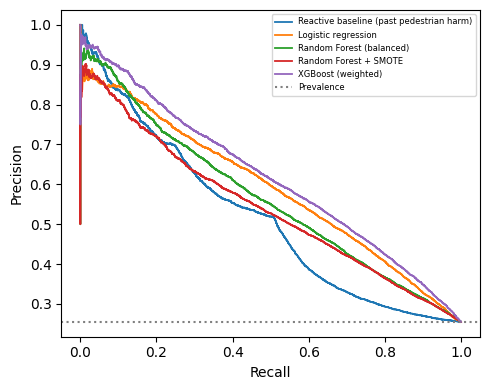

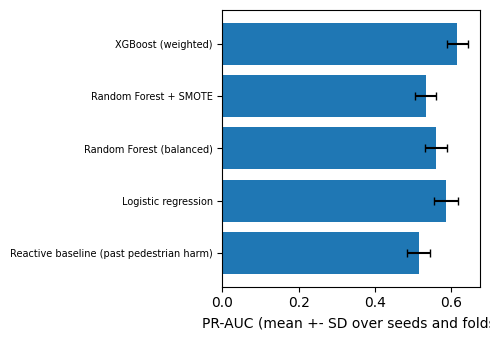

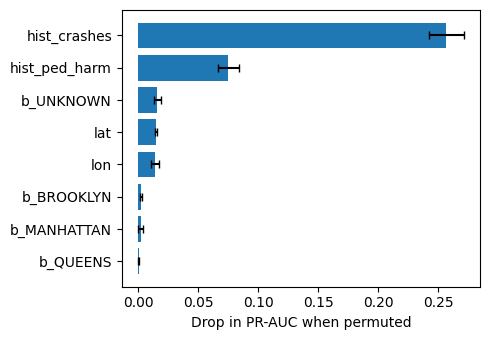

In [ ]:
order = [REACTIVE, LR, RF, RF_SM, XGB]

plt.figure(figsize=(5, 4))
for name in order:
    p, r, _ = precision_recall_curve(y, S[name])
    plt.plot(r, p, label=name, lw=1.3)
plt.axhline(y.mean(), ls=":", color="gray", label="Prevalence")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.legend(fontsize=6); plt.tight_layout()
plt.savefig("fig_pr_curves.pdf"); plt.show()

plt.figure(figsize=(5, 3.5))
means = [res[res.model == n]["PR-AUC"].mean() for n in order]
sds = [res[res.model == n]["PR-AUC"].std() for n in order]
plt.barh(range(len(order)), means, xerr=sds, capsize=3)
plt.yticks(range(len(order)), order, fontsize=7); plt.xlabel("PR-AUC (mean +- SD over seeds and folds)")
plt.tight_layout(); plt.savefig("fig_prauc_models.pdf"); plt.show()

top = imp_df.head(8).iloc[::-1]
plt.figure(figsize=(5, 3.5))
plt.barh(top["feature"], top["mean"], xerr=top["sd"], capsize=3)
plt.xlabel("Drop in PR-AUC when permuted"); plt.tight_layout()
plt.savefig("fig_importance.pdf"); plt.show()

In [ ]:
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| imbalanced-learn", imblearn.__version__)
print("CPU count:", os.cpu_count(), "| platform:", platform.platform())
print("Seeds:", SEEDS, "| spatial folds:", N_FOLDS, "| bootstrap resamples:", B)
print("Total running time: %.1f min" % ((time.time() - T0) / 60))

try:
    from google.colab import files
    os.system("zip -q results.zip fig_*.pdf table_*.csv cv_results.csv")
    files.download("results.zip")
except Exception as e:
    print("Download skipped:", e)

Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | xgboost 3.4.1 | imbalanced-learn 0.14.2
CPU count: 2 | platform: Linux-6.6.122+-x86_64-with-glibc2.39
Seeds: [0, 1, 2, 3, 4] | spatial folds: 5 | bootstrap resamples: 500
Total running time: 26.9 min


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>